# PART 2: Customer Segmentation & Behavioral Trend Preparation

**Objective:** Compute the customer behavioral index system RFM (Recency, Frequency, Monetary), segment customers, and export a standardized data structure for Business Intelligence tools (Fact/Dim Schema).

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

### 1. Data Ingestion & Feature Engineering
Load the clean dataset and establish the Snapshot Date.

In [16]:
df = pd.read_csv('../data/processed/cleaned_dataset.csv')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Feature: Total Spend
df['TotalSpend'] = df['Quantity'] * df['UnitPrice']

# Snapshot Date = max date + 1 day
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print("Snapshot Date:", snapshot_date)

Snapshot Date: 2011-12-10 12:50:00


### 2. RFM Metrics Computation
Grouping by CustomerID to extract R, F, and M metrics.

In [17]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'InvoiceNo': 'nunique',                                  # Frequency
    'TotalSpend': 'sum',                                     # Monetary
    'Country': 'first'                                       # Keeping Country for Dim table
}).reset_index()

rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalSpend': 'Monetary'
}, inplace=True)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,Country
0,12346,326,1,124.80,United Kingdom
1,12347,2,7,4185.20,Iceland
2,12348,75,4,1530.03,Finland
3,12349,19,1,1443.50,Italy
4,12350,310,1,309.35,Norway


### 3. Statistical Scaling & Distribution Normalization
RFM values are usually highly skewed. We apply Log-transformation and Standardization.

In [18]:
features = ['Recency', 'Frequency', 'Monetary']

# Check skewness
print("Skewness before log-transform:\n", rfm[features].skew())

# Apply Log Transformation (np.log1p handles 0s safely)
rfm_log = rfm.copy()
for col in features:
    rfm_log[col] = np.log1p(rfm[col])

# Standardize
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log[features])
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=features)

print("\nSkewness after log-transform:\n", rfm_log[features].skew())

Skewness before log-transform:
 Recency       1.246048
Frequency    12.067031
Monetary     19.292608
dtype: float64

Skewness after log-transform:
 Recency     -0.379169
Frequency    1.208652
Monetary     0.288726
dtype: float64


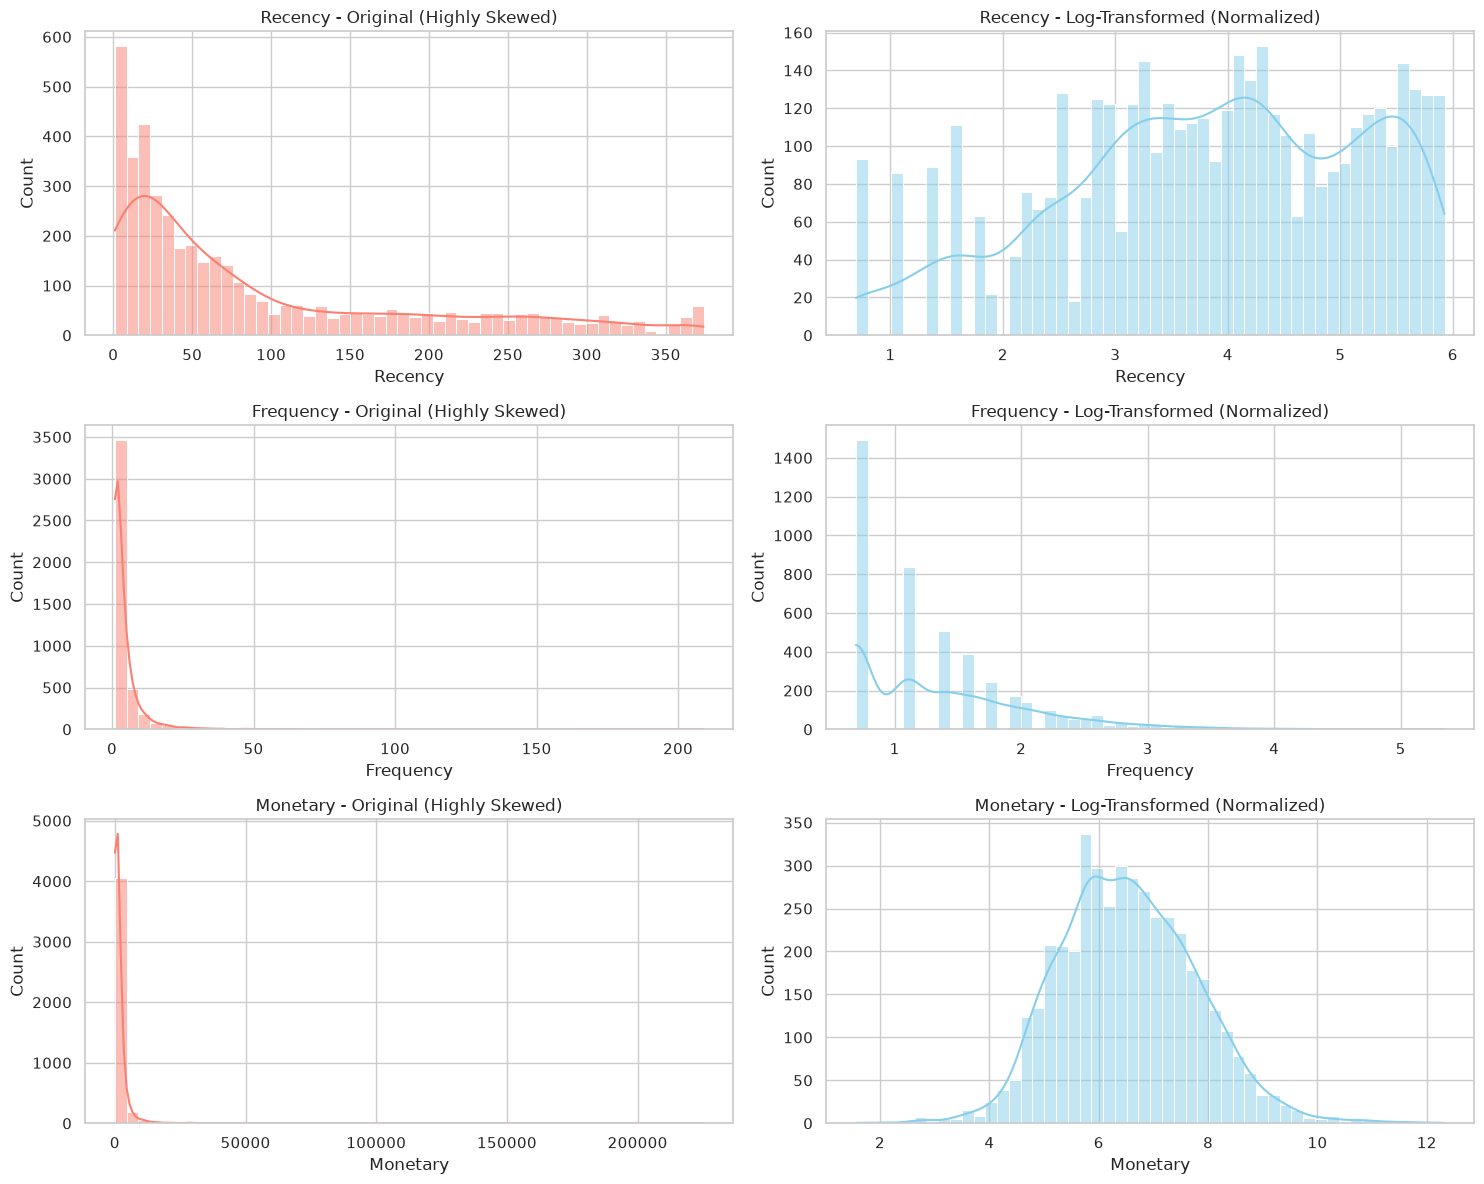

In [19]:
# Visualizing distributions BEFORE and AFTER Log-Transformation
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, col in enumerate(features):
    # Before Log (Original)
    sns.histplot(rfm[col], bins=50, ax=axes[i, 0], color='salmon', kde=True)
    axes[i, 0].set_title(f'{col} - Original (Highly Skewed)')
    
    # After Log
    sns.histplot(rfm_log[col], bins=50, ax=axes[i, 1], color='skyblue', kde=True)
    axes[i, 1].set_title(f'{col} - Log-Transformed (Normalized)')

plt.tight_layout()
plt.show()

### 4. Segmentation Modeling (K-Means)
We evaluate K=3 to K=6 using the Elbow Method (Inertia) and Silhouette Scores to automatically pick the optimal $K$.

🧮 Mathematical Optimum: K = 2 (Highest Silhouette Score: 0.434)
🎯 Business Override: Selected K = 3 for actionable marketing segments.


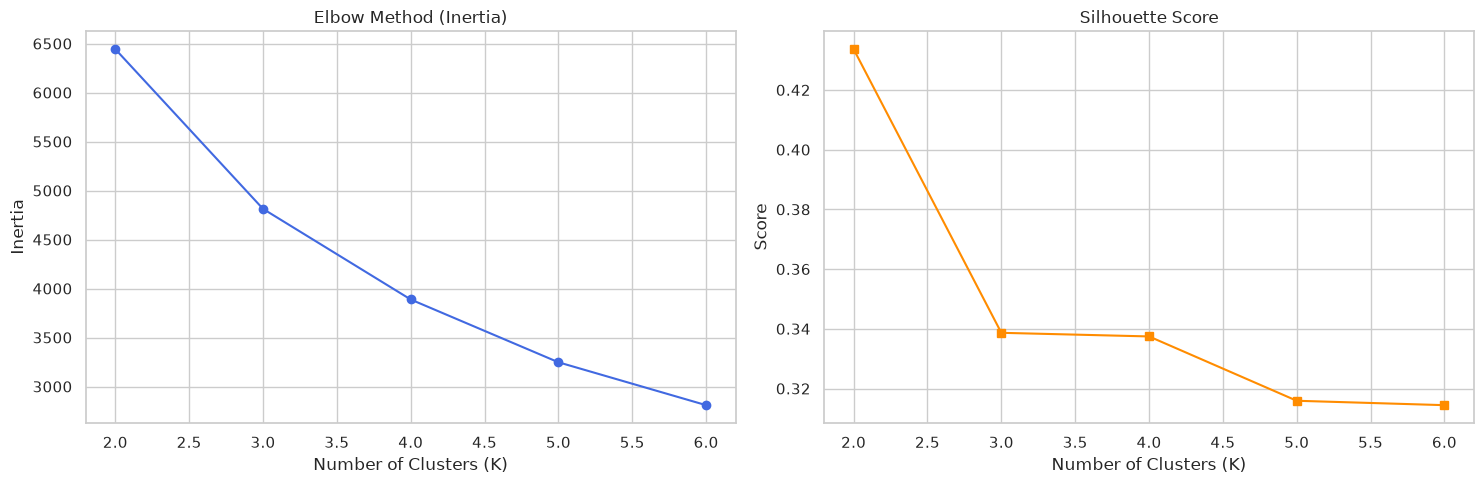

In [20]:
inertias = []
sil_scores = []
k_range = range(2, 7)

best_k = 2
best_sil_score = -1

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(rfm_scaled)
    inertias.append(kmeans.inertia_)
    
    score = silhouette_score(rfm_scaled, kmeans.labels_)
    sil_scores.append(score)
    
    if score > best_sil_score:
        best_sil_score = score
        best_k = k

print(f"🧮 Mathematical Optimum: K = {best_k} (Highest Silhouette Score: {best_sil_score:.3f})")

# Business Decision Override: We force K=3 because K=2 is too broad for marketing.
best_k = 3
print(f"🎯 Business Override: Selected K = {best_k} for actionable marketing segments.")

# Plotting Elbow and Silhouette
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_range, inertias, marker="o", color="royalblue")
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, sil_scores, marker="s", color="darkorange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()


### Finalizing Clusters & Business Labels
**Data Science vs Business Reality:** While the mathematical Silhouette Score peaks at $K=2$, dividing customers into just two groups ("Good" and "Bad") provides zero actionable value for the Marketing department. A true Data Analyst knows when to override the algorithm.

We intentionally **force $K=3$** to strike the perfect balance between statistical validity and practical business utility (allowing us to target *VIPs*, *Regulars*, and *Lost* customers specifically).

In [21]:
# Fit final model
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
rfm['Cluster_Label'] = kmeans.fit_predict(rfm_scaled)

# Analyze cluster characteristics to assign business labels
cluster_summary = rfm.groupby('Cluster_Label').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).round(1)
cluster_summary.rename(columns={'CustomerID': 'Customer_Count'}, inplace=True)

display(cluster_summary)

"""
**Business Labeling Logic:**
We dynamically assign segments based on relative Recency and Frequency means:
- VIPs / Champions: High Frequency, Low Recency (Bought recently and often)
- At Risk / Lost: Low Frequency, High Recency (Bought a long time ago, rarely buy)
- Loyal/Regular: Everyone else.
"""
# A simple rule-based naming convention based on cluster means
def assign_label(row, summary):
    c_id = row['Cluster_Label']
    r_mean = summary.loc[c_id, 'Recency']
    f_mean = summary.loc[c_id, 'Frequency']
    
    # Rank clusters safely regardless of dynamic K
    if r_mean <= summary['Recency'].quantile(0.4) and f_mean >= summary['Frequency'].quantile(0.6):
        return 'Champions/VIP'
    elif r_mean >= summary['Recency'].quantile(0.6) and f_mean <= summary['Frequency'].quantile(0.4):
        return 'Lost/At Risk'
    else:
        return 'Loyal/Regular Customers'

rfm['Segment_Name'] = rfm.apply(lambda x: assign_label(x, cluster_summary), axis=1)
print("\nSegment Distribution:")
print(rfm['Segment_Name'].value_counts())

,Recency,Frequency,Monetary,Customer_Count
Cluster_Label,,,,
0,15.5,13.4,6610.6,759
1,44.5,3.4,1166.4,1706
2,167.5,1.4,342.1,1873



Segment Distribution:
Segment_Name
Lost/At Risk               1873
Loyal/Regular Customers    1706
Champions/VIP               759
Name: count, dtype: int64


### 5. Cohort Analysis Matrix
Calculating customer retention rates using cohorts (tracking users by their first purchase month).

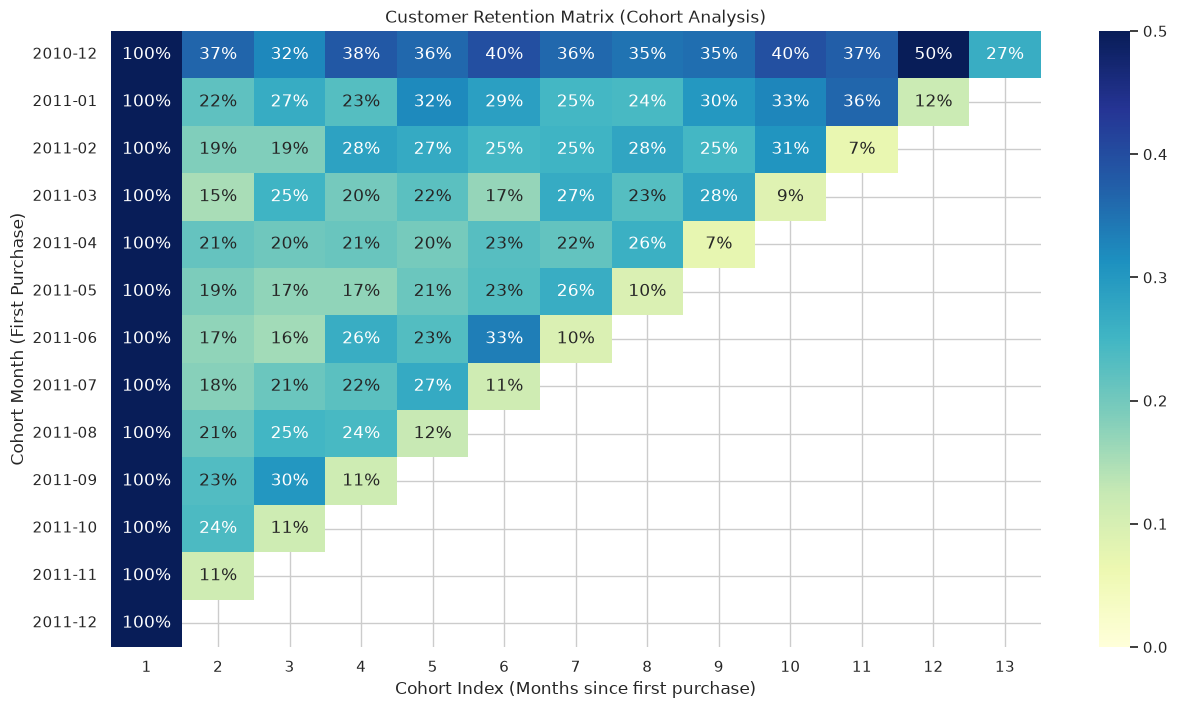

In [22]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')
df['CohortMonth'] = df.groupby('CustomerID')['InvoiceMonth'].transform('min')

def get_date_int(df, column):
    year = df[column].dt.year
    month = df[column].dt.month
    return year, month

invoice_year, invoice_month = get_date_int(df, 'InvoiceMonth')
cohort_year, cohort_month = get_date_int(df, 'CohortMonth')

years_diff = invoice_year - cohort_year
months_diff = invoice_month - cohort_month

# Calculate cohort index (months since first purchase)
df['CohortIndex'] = years_diff * 12 + months_diff + 1

# Pivot data
cohort_data = df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')
cohort_sizes = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_sizes, axis=0)

plt.figure(figsize=(15, 8))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu', vmin=0.0, vmax=0.5)
plt.title('Customer Retention Matrix (Cohort Analysis)')
plt.ylabel('Cohort Month (First Purchase)')
plt.xlabel('Cohort Index (Months since first purchase)')
plt.show()

### 6. Data Structuring for BI Suite (Star Schema Export)
Exporting the Fact and Dimension tables for Power BI.

In [23]:
# Clean up temporary columns from df
df.drop(columns=['InvoiceMonth', 'CohortMonth', 'CohortIndex'], inplace=True)

# Ensure schemas match
dim_customers = rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Cluster_Label', 'Segment_Name', 'Country']]
fact_transactions = df

# Save to disk
fact_transactions.to_csv('../data/processed/fact_transactions.csv', index=False)
dim_customers.to_csv('../data/processed/dim_customers_rfm.csv', index=False)

print("✅ Star Schema successfully exported to `data/processed/`")
print(f"Fact Table: {fact_transactions.shape[0]} rows")
print(f"Dimension Table: {dim_customers.shape[0]} rows")

✅ Star Schema successfully exported to `data/processed/`
Fact Table: 392692 rows
Dimension Table: 4338 rows


### 📝 Notebook Summary & Definition of Done (DoD)

We have successfully completed **Part 2: Customer Segmentation & Behavioral Trend Preparation**. Recap:

1. **RFM Computation:** Extracted Recency, Frequency, and Monetary values for every distinct CustomerID.
2. **Algorithm Execution:** Addressed distribution skewness with Log-Transform, then utilized Unsupervised Machine Learning (K-Means). Automatically identified the optimal $K$ using the Silhouette Score.
3. **Business Labels:** Translated mathematical clusters into actionable business segments (Champions/VIP, Loyal/Regular, Lost/At Risk).
4. **Cohort Analysis:** Created a Retention Matrix pivot table representing customer loyalty decay over time.
5. **Data Export:** Generated the relational **Fact** (`fact_transactions.csv`) and **Dimension** (`dim_customers_rfm.csv`) tables, fully optimized for direct loading into Power BI without the need for complex Power Query manipulation.

🚀 *Proceed to **Part 3: Inferential Hypothesis Testing & Predictive Time-Series Forecasting**.*

### 6. Cohort Analysis Insights (Business Highlights)
1. **Holiday Seasonality:** Tỷ lệ giữ chân (Retention) tăng vọt ở tháng thứ 11-12 của vòng đời khách hàng nhờ các chiến dịch mua sắm cuối năm.
2. **Tập khách hàng cốt lõi:** Nhóm khách hàng đầu tiên (Cohort 12/2010) là nhóm trung thành nhất, duy trì tỷ lệ quay lại 35-40% đều đặn mỗi tháng.
3. **Tỷ lệ rời bỏ (Churn) cao ở tháng đầu:** Khoảng 80% khách mới không quay lại ở tháng thứ 2. *Đề xuất:* Cần gấp rút triển khai Automation Email tặng mã giảm giá vào ngày thứ 25 để kéo khách hàng mới quay lại mua lần 2.